# 06 Small-object Resolution Calibration

**Objective:** select one input-resolution and batch-size profile for the
locked model and augmentation policy using validation evidence only.

**Success criteria:** compare exactly the configured 640/960/1280 profiles,
prioritize helmet recall, retain one compact comparison record, and keep the
independent test set unavailable throughout this notebook.


## Setup and lock upstream decisions

`DRY_RUN=True` validates all profile contracts without training. A real run
requires a completed Notebook 05 ablation result. Set
`RESOLUTION_EXPERIMENT_OVERRIDE` before calibration only when a deliberate
augmentation policy must be calibrated regardless of Notebook 05's winner.


In [1]:
# Purpose: initialize validation-only resolution calibration from locked upstream decisions.
# Inputs: Notebook 05 metadata, its exact augmentation artifact, tracked profiles, and optional explicit run IDs.
# Guard: copy only train/validation manifests; a real run requires completed ablation metadata and never resolves test data.
# Output: one immutable resolution-calibration run with complete upstream provenance.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import Markdown, display

from src.analysis.plot_utils import plot_metric_comparison
from src.artifacts import (
    create_run,
    find_latest_run,
    open_run,
    read_run_metadata,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.config import (
    find_project_root,
    get_experiment,
    load_pipeline_config,
    online_augmentation_args,
    resolve_final_experiment,
)
from src.dataset.manifests import (
    copy_manifest,
    experiment_manifest,
    manifest_sha256,
    write_ultralytics_dataset_yaml,
)
from src.training.evaluate_yolo import benchmark_model_latency, evaluate_model
from src.training.train_yolo import (
    build_train_args,
    clean_training_intermediates,
    format_progress_event,
    rank_results,
    run_training_specs,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
TRAINING_CONFIG = CONFIG["training"]
SEED = int(TRAINING_CONFIG["seed"])

# Optional reproducibility pins. None uses the newest matching artifact.
SOURCE_ABLATION_RUN = None
SOURCE_AUGMENTATION_RUN = None
# Example deliberate override: "exp_D_full_pipeline".
RESOLUTION_EXPERIMENT_OVERRIDE = None
DRY_RUN = False

ABLATION_RUN = (
    open_run(SOURCE_ABLATION_RUN)
    if SOURCE_ABLATION_RUN
    else find_latest_run(V2_ROOT, "ablation", "csv/ablation_results.csv")
)
ablation_metadata = read_run_metadata(ABLATION_RUN)
if not DRY_RUN and ablation_metadata.get("status") != "completed":
    raise RuntimeError(f"Ablation run is not completed: {ABLATION_RUN.run_id}")

selected_model = ablation_metadata.get("selected_model")
ablation_selected_experiment = ablation_metadata.get("selected_experiment")
if DRY_RUN:
    # Fallbacks validate wiring only; they never authorize a real final run.
    selected_model = selected_model or TRAINING_CONFIG["candidate_models"][0]
    ablation_selected_experiment = (
        ablation_selected_experiment or TRAINING_CONFIG["candidate_experiment"]
    )
if not selected_model or not ablation_selected_experiment:
    raise RuntimeError("Completed Notebook 05 metadata must lock model and experiment")

selected_experiment, experiment_selection_source = resolve_final_experiment(
    CONFIG,
    str(ablation_selected_experiment),
    str(RESOLUTION_EXPERIMENT_OVERRIDE) if RESOLUTION_EXPERIMENT_OVERRIDE else None,
)

upstream_augmentation_id = ablation_metadata.get("source_augmentation_run")
if SOURCE_AUGMENTATION_RUN:
    AUGMENTATION_RUN = open_run(SOURCE_AUGMENTATION_RUN)
elif upstream_augmentation_id:
    # Follow Notebook 05's exact data artifact, not an accidentally newer one.
    AUGMENTATION_RUN = open_run(V2_ROOT / "artifacts" / str(upstream_augmentation_id))
elif DRY_RUN:
    AUGMENTATION_RUN = find_latest_run(
        V2_ROOT,
        "augmentation-qa",
        "manifests/train_original_plus_offline.txt",
    )
else:
    raise RuntimeError("Ablation metadata does not identify its augmentation run")

RUN = create_run(
    V2_ROOT,
    "resolution-calibration",
    f"{Path(str(selected_model)).stem}-{selected_experiment}",
    SEED,
)
for manifest_name in (
    "train_original.txt",
    "train_original_plus_offline.txt",
    "val.txt",
):
    copy_manifest(
        AUGMENTATION_RUN.manifests / manifest_name,
        RUN.manifests / manifest_name,
    )

write_run_metadata(
    RUN,
    {
        "stage": "resolution-calibration",
        "status": "started",
        "dry_run": DRY_RUN,
        "seed": SEED,
        "selected_model": str(selected_model),
        "ablation_selected_experiment": str(ablation_selected_experiment),
        "resolution_experiment_override": RESOLUTION_EXPERIMENT_OVERRIDE,
        "experiment_selection_source": experiment_selection_source,
        "selected_experiment": selected_experiment,
        "source_ablation_run": ABLATION_RUN.run_id,
        "source_candidate_run": ablation_metadata.get("source_candidate_run"),
        "source_augmentation_run": AUGMENTATION_RUN.run_id,
        "resolution_profiles": TRAINING_CONFIG["resolution_profiles"],
        "resolution_selection_priority": TRAINING_CONFIG[
            "resolution_selection_priority"
        ],
        "runtime": runtime_metadata(V2_ROOT),
    },
)


WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260826T083333Z_resolution-calibration_yolo12n-exp-d-full-pipeline_s42_027537d/run.yaml')

#### Observation

TODO after execution:

- Confirm the model and augmentation experiment match the intended decision.
- Record explicit source run IDs when reproducing a report.
- Confirm this artifact contains train/validation manifests only.


## Materialize one shared validation contract

Every profile uses the same initialization, membership, augmentation policy,
seed, epoch budget, and runtime settings. Only `imgsz` and its reviewed
`batch` pair change.


In [2]:
# Purpose: materialize the single dataset and bounded resolution profile matrix.
# Inputs: selected experiment, copied train variants, validation manifest, and tracked profiles.
# Guard: write one train/val YAML without a test key and rely on config validation to reject profile drift.
# Output: one dataset YAML plus a compact settings table for review before training.
experiment = get_experiment(CONFIG, selected_experiment)
original_manifest = RUN.manifests / "train_original.txt"
combined_manifest = RUN.manifests / "train_original_plus_offline.txt"
val_manifest = RUN.manifests / "val.txt"
train_manifest = experiment_manifest(
    experiment,
    original_manifest,
    combined_manifest,
)
resolution_dataset_yaml = write_ultralytics_dataset_yaml(
    RUN.manifests / "resolution_dataset.yaml",
    train_manifest,
    val_manifest,
    CONFIG["classes"],
)

profile_df = pd.DataFrame(TRAINING_CONFIG["resolution_profiles"])
profile_df.insert(0, "model", str(selected_model))
profile_df["experiment"] = selected_experiment
profile_df["online_augmentation"] = bool(experiment["online_augmentation"])
profile_df["epochs"] = int(TRAINING_CONFIG["resolution_epochs"])
profile_df["validation_only_selection"] = True
display(profile_df)


,model,name,imgsz,batch,experiment,online_augmentation,epochs,validation_only_selection
0,yolo12n.pt,img640,640,32,exp_D_full_pipeline,True,100,True
1,yolo12n.pt,img960,960,16,exp_D_full_pipeline,True,100,True
2,yolo12n.pt,img1280,1280,8,exp_D_full_pipeline,True,100,True


#### Observation

TODO after execution:

- Confirm exactly `img640`, `img960`, and `img1280` are present.
- Check each larger input uses its paired smaller batch size.
- Confirm every non-resolution setting is identical across rows.


## Train each resolution profile sequentially

Profiles run one at a time to bound GPU memory. Early stopping uses the shared
patience setting. Each row's `best.pt` is evaluated on the same validation
split; one updating panel keeps output compact.


In [3]:
# Purpose: train the three reviewed size/batch profiles through the shared helper.
# Inputs: one dataset YAML, selected model/augmentation, and profile-specific imgsz/batch pairs.
# Guard: run sequentially with distinct names and continue after one failure for an auditable comparison.
# Output: one compact row per profile and a bounded in-place progress panel.
resolution_progress = display(
    Markdown("Resolution calibration is waiting to start."),
    display_id=True,
)


def update_resolution_progress(event: dict) -> None:
    """Render one compact profile/epoch event in the existing output panel."""
    resolution_progress.update(Markdown(format_progress_event(event)))


profile_result_frames = []
for profile in TRAINING_CONFIG["resolution_profiles"]:
    profile_name = str(profile["name"])
    profile_train_args = build_train_args(TRAINING_CONFIG, "resolution_epochs")
    # Image size and batch form one reviewed pair for memory safety.
    profile_train_args.update(
        {"imgsz": int(profile["imgsz"]), "batch": int(profile["batch"])}
    )
    profile_spec = {
        "run_name": f"resolution-{profile_name}-{Path(str(selected_model)).stem}",
        "model_name": str(selected_model),
        "experiment": selected_experiment,
        "data_yaml": resolution_dataset_yaml,
        "online_augmentation": bool(experiment["online_augmentation"]),
        "augmentation_args": online_augmentation_args(
            CONFIG["augmentation"],
            enabled=bool(experiment["online_augmentation"]),
        ),
    }
    profile_result = run_training_specs(
        [profile_spec],
        RUN.models,
        profile_train_args,
        dry_run=DRY_RUN,
        continue_on_error=True,
        progress_callback=update_resolution_progress,
    )
    profile_result.insert(0, "resolution_profile", profile_name)
    profile_result.insert(1, "imgsz", int(profile["imgsz"]))
    profile_result.insert(2, "batch", int(profile["batch"]))
    profile_result_frames.append(profile_result)

resolution_results_df = pd.concat(profile_result_frames, ignore_index=True)
display(
    resolution_results_df[
        ["resolution_profile", "imgsz", "batch", "status", "error_message"]
    ]
)


**[1/1] resolution-img1280-yolo12n** · yolo12n.pt — **completed** | R=0.9104 | mAP50=0.9419 | mAP50-95=0.6408 | elapsed=1:04:28

,resolution_profile,imgsz,batch,status,error_message
0,img640,640,32,trained,
1,img960,960,16,trained,
2,img1280,1280,8,trained,


#### Observation

TODO after execution:

- Record any OOM or unsupported profile without changing other profiles.
- Compare elapsed time as an operational cost, not as the accuracy winner.
- Verify a dry run reports three valid contracts before enabling training.


## Evaluate helmet performance and rank profiles

Re-evaluate every successful `best.pt` on validation at its own input size.
Selection is lexicographic: helmet recall, helmet mAP50-95, overall mAP50-95,
then FPS. This makes the small-object safety requirement explicit.


val: Scanning C:\Github\smart-factory-safety-monitoring-system\ppe-detection\v2_pipeline\data\input\factory_source\labels.cache... 172 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 5.9it/s 1.9s.2s
val: Scanning C:\Github\smart-factory-safety-monitoring-system\ppe-detection\v2_pipeline\data\input\factory_source\labels.cache... 172 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 5.2it/s 2.1s0.1s
val: Scanning C:\Github\smart-factory-safety-monitoring-system\ppe-detection\v2_pipeline\data\input\factory_source\labels.cache... 172 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.6it/s 3.0s0.2s


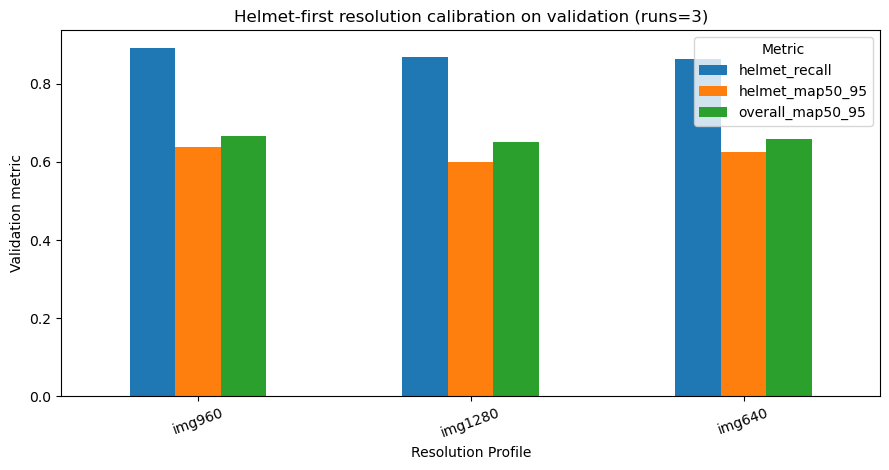

,rank,resolution_profile,imgsz,batch,status,helmet_recall,helmet_map50_95,overall_map50_95,fps
0,1,img960,960,16,trained,0.891547,0.637543,0.666887,12.502726
1,2,img1280,1280,8,trained,0.868974,0.598499,0.65161,12.457482
2,3,img640,640,32,trained,0.864035,0.625757,0.658912,12.765326


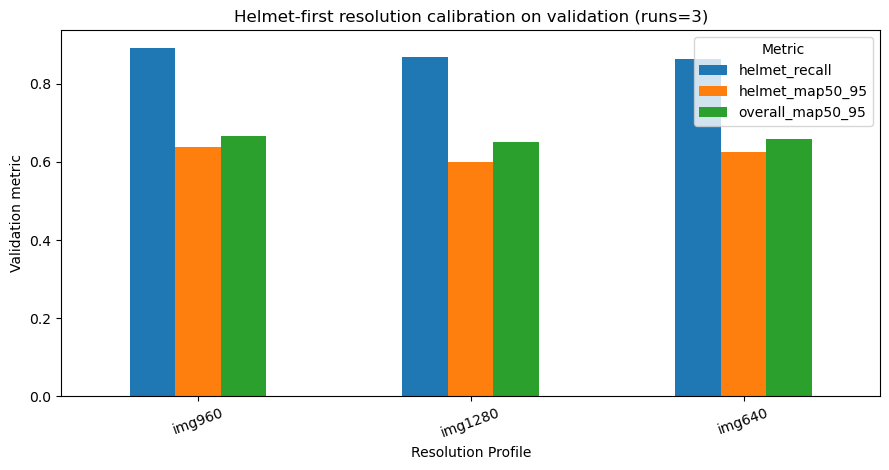

In [4]:
# Purpose: collect comparable overall, helmet-specific, and latency evidence from validation only.
# Inputs: successful best checkpoints, shared validation data, and helmet-first ranking priority.
# Guard: evaluate with matching imgsz; mark failures explicitly and never access independent test data.
# Output: ranked CSV, optional failure CSV, one figure, and a compact decision table.
metric_columns = (
    "helmet_precision",
    "helmet_recall",
    "helmet_map50",
    "helmet_map50_95",
    "overall_precision",
    "overall_recall",
    "overall_map50",
    "overall_map50_95",
    "avg_inference_ms",
    "fps",
)
for metric_name in metric_columns:
    if metric_name not in resolution_results_df:
        resolution_results_df[metric_name] = None

if not DRY_RUN:
    for row_index, row in resolution_results_df.iterrows():
        checkpoint = Path(str(row["best_weights_path"]))
        if row["status"] != "trained" or not checkpoint.is_file():
            continue
        try:
            evaluation = evaluate_model(
                checkpoint,
                resolution_dataset_yaml,
                split="val",
                imgsz=int(row["imgsz"]),
                device=TRAINING_CONFIG["device"],
            )
            for metric_name, value in evaluation["overall"].items():
                resolution_results_df.loc[row_index, f"overall_{metric_name}"] = value
            helmet_rows = evaluation["class_metrics"].loc[
                evaluation["class_metrics"]["class_name"].eq("helmet")
            ]
            if helmet_rows.empty:
                raise RuntimeError("Validation output contains no helmet metrics")
            for metric_name in ("precision", "recall", "map50", "map50_95"):
                resolution_results_df.loc[row_index, f"helmet_{metric_name}"] = (
                    helmet_rows.iloc[0][metric_name]
                )
            latency = benchmark_model_latency(
                checkpoint,
                val_manifest,
                imgsz=int(row["imgsz"]),
                device=TRAINING_CONFIG["device"],
                max_images=int(TRAINING_CONFIG["latency_max_images"]),
            )
            for metric_name, value in latency.items():
                resolution_results_df.loc[row_index, metric_name] = value
        except Exception as exc:
            resolution_results_df.loc[row_index, "status"] = "failed"
            resolution_results_df.loc[row_index, "error_message"] = (
                f"Post-training validation failed: {exc}"
            )

ranked_resolution_df = rank_results(
    resolution_results_df,
    TRAINING_CONFIG["resolution_selection_priority"],
)
results_path = RUN.csv / "resolution_calibration_results.csv"
ranked_resolution_df.to_csv(results_path, index=False)
failures_df = ranked_resolution_df.loc[ranked_resolution_df["status"].eq("failed")]
if not failures_df.empty:
    failures_df.to_csv(RUN.csv / "resolution_calibration_failures.csv", index=False)

comparison_figure_path = None
trained_resolution_df = ranked_resolution_df.loc[
    ranked_resolution_df["status"].eq("trained")
]
if not trained_resolution_df.empty:
    comparison_figure_path = RUN.figures / "helmet_resolution_validation_comparison.png"
    comparison_figure = plot_metric_comparison(
        trained_resolution_df,
        "resolution_profile",
        ("helmet_recall", "helmet_map50_95", "overall_map50_95"),
        comparison_figure_path,
        "Helmet-first resolution calibration on validation",
    )
    display(comparison_figure)

display_columns = [
    "rank",
    "resolution_profile",
    "imgsz",
    "batch",
    "status",
    "helmet_recall",
    "helmet_map50_95",
    "overall_map50_95",
    "fps",
]
display(ranked_resolution_df[display_columns])


#### Observation

TODO after execution:

- Record whether larger input materially improves helmet recall.
- Compare gain against mAP50-95 and FPS; note failed/OOM profiles.
- Do not use any later test result to revise this ranking.


## Lock the selected profile and clean intermediates

Notebook 07 retrains from the original model checkpoint, so Notebook 06 keeps
the compact CSV/figure/metadata decision record instead of three redundant
model trees. Cleanup is restricted to this newly created run.


In [5]:
# Purpose: persist the selected resolution profile and apply bounded artifact retention.
# Inputs: ranked validation rows, manifest hashes, comparison artifact, and retention setting.
# Guard: remove only current-run internals after results exist; never delete source data or historical runs.
# Output: run.yaml containing the exact imgsz/batch consumed by Notebook 07.
selected_profile = None
selected_imgsz = None
selected_batch = None
selected_metrics = {}
if not trained_resolution_df.empty:
    selected_row = trained_resolution_df.iloc[0]
    selected_profile = str(selected_row["resolution_profile"])
    selected_imgsz = int(selected_row["imgsz"])
    selected_batch = int(selected_row["batch"])
    for metric_name in TRAINING_CONFIG["resolution_selection_priority"]:
        value = selected_row.get(metric_name)
        selected_metrics[metric_name] = (
            float(value) if value is not None and pd.notna(value) else None
        )

if not DRY_RUN and not bool(TRAINING_CONFIG["keep_intermediates"]):
    clean_training_intermediates(RUN.models)

run_status = "dry_run" if DRY_RUN else "completed" if selected_profile else "failed"
update_run_metadata(
    RUN,
    {
        "status": run_status,
        "selected_model": str(selected_model),
        "selected_experiment": selected_experiment,
        "selected_resolution_profile": selected_profile,
        "selected_imgsz": selected_imgsz,
        "selected_batch": selected_batch,
        "selected_validation_metrics": selected_metrics,
        "results_csv": str(results_path),
        "comparison_figure": str(comparison_figure_path)
        if comparison_figure_path
        else None,
        "train_manifest_sha256": manifest_sha256(train_manifest),
        "val_manifest_sha256": manifest_sha256(val_manifest),
    },
)
print(f"Resolution run: {RUN.run_id}")
print(f"Selected profile: {selected_profile or 'not selected'}")
print(f"Status: {run_status}")
if not DRY_RUN and not selected_profile:
    raise RuntimeError("No resolution profile completed validation successfully")


Resolution run: 20260826T083333Z_resolution-calibration_yolo12n-exp-d-full-pipeline_s42_027537d
Selected profile: img960
Status: completed


#### Observation

TODO after execution: record the immutable run ID, selected profile,
`imgsz`/`batch`, helmet trade-off, and whether the choice is operationally
acceptable for final training and deployment.
